# Por dónde pasaba el juego de España · Eurocopa femenina 2025

**Línea de pase** · Ángel Marqueta Alonso

Una red de pases convierte un partido en un grafo: cada jugadora es un nodo y cada flecha A → B pesa tantos pases completados como A dio a B. Con ella se puede ver quién recibe más, qué parejas conectan más y, sobre todo, por quién pasa el juego.

Este cuaderno sigue el análisis paso a paso con los seis partidos de España. El código está en `codigo/` y aquí solo se llama a sus funciones, para que el cuaderno y el programa den siempre lo mismo.

In [1]:
from pathlib import Path
import os, sys
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "cuadernos" else Path.cwd()
sys.path.insert(0, str(RAIZ / "codigo"))
CACHE = Path(os.environ.get("LINEA_CACHE", RAIZ / "datos" / "privados"))

from datos import EQUIPO, nombres_cortos, partidos_de_espana
from redes import analizar_partido, pases_de_red, minuto_corte
pd.set_option("display.width", 160)

## 1. Los datos

Los eventos salen de StatsBomb Open Data, con la descarga fijada a un commit para poder repetir el análisis. España jugó seis partidos: tres de grupos, cuartos, semifinal y final.

In [2]:
partidos, manifiesto, total = partidos_de_espana(CACHE)
print(f"Partidos del torneo: {total} · Partidos de España: {len(partidos)}")
pd.DataFrame([{k: p[k] for k in ("fecha", "fase", "rival", "goles_espana", "goles_rival")} for p in partidos])

Partidos del torneo: 31 · Partidos de España: 6


,fecha,fase,rival,goles_espana,goles_rival
0,2025-07-03,Group Stage,Portugal,5,0
1,2025-07-07,Group Stage,Belgium,6,2
2,2025-07-11,Group Stage,Italy,3,1
3,2025-07-18,Quarter-finals,Switzerland,2,0
4,2025-07-23,Semi-finals,Germany,1,0
5,2025-07-27,Final,England,1,1


## 2. Qué pases entran en la red

- Solo **pases completados** (en StatsBomb, los que no tienen `outcome`).
- Fuera los **saques** de banda, esquina, puerta, falta y centro: no son decisiones de circulación.
- Solo hasta el **primer cambio** de España, para que las once estén en el campo todo el tramo.

Un detalle que costó un error: StatsBomb sigue contando el descuento de la primera parte (minuto 46, 47…) y la segunda vuelve a empezar en el 45. Por eso el corte se compara como (parte, minuto) y no solo por minuto. Ante Portugal, el primer cambio fue en el descanso: con solo el minuto se habrían perdido los pases del descuento.

In [3]:
final = partidos[-1]
pases, corte = pases_de_red(final["eventos"], EQUIPO)
print(f"Final: corte en la parte {corte[0]}, minuto {corte[1]:.1f} · {len(pases)} pases en la red")
pases.head()

Final: corte en la parte 2, minuto 70.3 · 391 pases en la red


,pasadora,receptora,x,y,x_fin,y_fin
0,Alexia Putellas Segura,Olga Carmona García,15.2,3.9,8.8,1.2
1,Catalina Thomas Coll Lluch,Laia Aleixandri López,19.9,37.7,29.7,14.7
2,Laia Aleixandri López,Irene Paredes Hernandez,32.6,14.7,27.9,46.1
3,Irene Paredes Hernandez,Athenea del Castillo Belvide,33.6,51.9,54.3,73.9
4,Athenea del Castillo Belvide,Aitana Bonmati Conca,56.2,73.9,54.6,66.0


## 3. Red y medidas de cada partido

Para cada jugadora calculo:

- **pases_red**: pases dados más recibidos dentro de la red.
- **intermediacion**: qué parte de los caminos más cortos entre compañeras pasa por ella. La distancia de cada flecha es 1 / número de pases, para que más pases signifique más cerca.
- **pagerank**: importancia de recibir de jugadoras que a su vez reciben mucho.

Y para el equipo, la **centralización** (0 = juego repartido, 1 = todo pasa por una jugadora).

In [4]:
filas = []
for p in partidos:
    nombres = nombres_cortos(p["alineaciones"])
    _, _, tabla, resumen = analizar_partido(p, EQUIPO)
    resumen["jugadora_mas_central"] = nombres[resumen["jugadora_mas_central"]]
    filas.append(resumen)
resumen = pd.DataFrame(filas)
resumen[["fase", "rival", "resultado", "minutos_red", "pases_red", "pases_por_minuto", "centralizacion", "jugadora_mas_central"]]

,fase,rival,resultado,minutos_red,pases_red,pases_por_minuto,centralizacion,jugadora_mas_central
0,Group Stage,Portugal,5-0,48.0,306,6.37,0.476,Laia Aleixandri
1,Group Stage,Belgium,6-2,46.2,367,7.95,0.439,Patri Guijarro
2,Group Stage,Italy,3-1,61.4,488,7.94,0.413,María Méndez
3,Quarter-finals,Switzerland,2-0,63.7,398,6.24,0.271,Olga Carmona
4,Semi-finals,Germany,1-0,68.4,387,5.66,0.486,Patri Guijarro
5,Final,England,1-1,71.6,391,5.46,0.464,Laia Aleixandri


## 4. Comprobaciones

Antes del primer cambio solo pueden aparecer titulares; la suma de los grados tiene que ser el doble de los pases (cada pase cuenta una vez para quien lo da y otra para quien lo recibe); y no puede haber coordenadas fuera del campo (120 × 80 en StatsBomb). El programa principal detiene el análisis si algo de esto falla.

In [5]:
for p in partidos:
    pases, _, tabla, _ = analizar_partido(p, EQUIPO)
    once = next(e for e in p["eventos"] if e["type"]["name"] == "Starting XI" and e["team"]["name"] == EQUIPO)
    titulares = {j["player"]["name"] for j in once["tactics"]["lineup"]}
    assert (set(pases.pasadora) | set(pases.receptora)) <= titulares
    assert tabla.pases_red.sum() == 2 * len(pases)
    assert pases[["x", "x_fin"]].le(120).all().all() and pases[["y", "y_fin"]].le(80).all().all()
print("Todas las comprobaciones pasan")

Todas las comprobaciones pasan


## 5. Lo que dicen los resultados

Las medias del torneo, solo para jugadoras con al menos tres redes (con una o dos, la media dice poco):

In [6]:
torneo = pd.read_csv(RAIZ / "datos" / "salida" / "jugadoras_torneo.csv")
torneo[torneo.redes >= 3][["nombre", "redes", "pases_red_media", "intermediacion_media", "pagerank_medio"]].round(3)

,nombre,redes,pases_red_media,intermediacion_media,pagerank_medio
0,Laia Aleixandri,4,102.250,0.299,0.124
1,María Méndez,3,89.667,0.220,0.096
2,Irene Paredes,5,97.600,0.219,0.101
3,Patri Guijarro,6,93.667,0.161,0.108
5,Mariona Caldentey,6,84.500,0.144,0.114
6,Ona Batlle,5,77.200,0.098,0.100
7,Olga Carmona,5,70.600,0.091,0.100
8,Aitana Bonmatí,4,92.250,0.076,0.114
9,Alexia Putellas,6,72.167,0.057,0.102
11,Claudia Pina,4,57.500,0.015,0.093


- El juego de España pasaba sobre todo por la **defensa y la mediocentro**: Laia Aleixandri, María Méndez, Irene Paredes y Patri Guijarro son las que más caminos unen.
- En la fase de grupos España completó entre 6,4 y 8 pases por minuto; en las eliminatorias, entre 5,5 y 6,2. Los rivales eran mejores y el partido, más cerrado.
- Ante Suiza la red fue la más repartida (centralización 0,27); en la semifinal y la final, de las más concentradas.

**Límites.** Solo pases completados (ni conducciones ni pérdidas); el corte en el primer cambio deja fuera el final de cada partido; la posición media mezcla ataque y defensa; seis partidos no permiten sacar reglas generales.

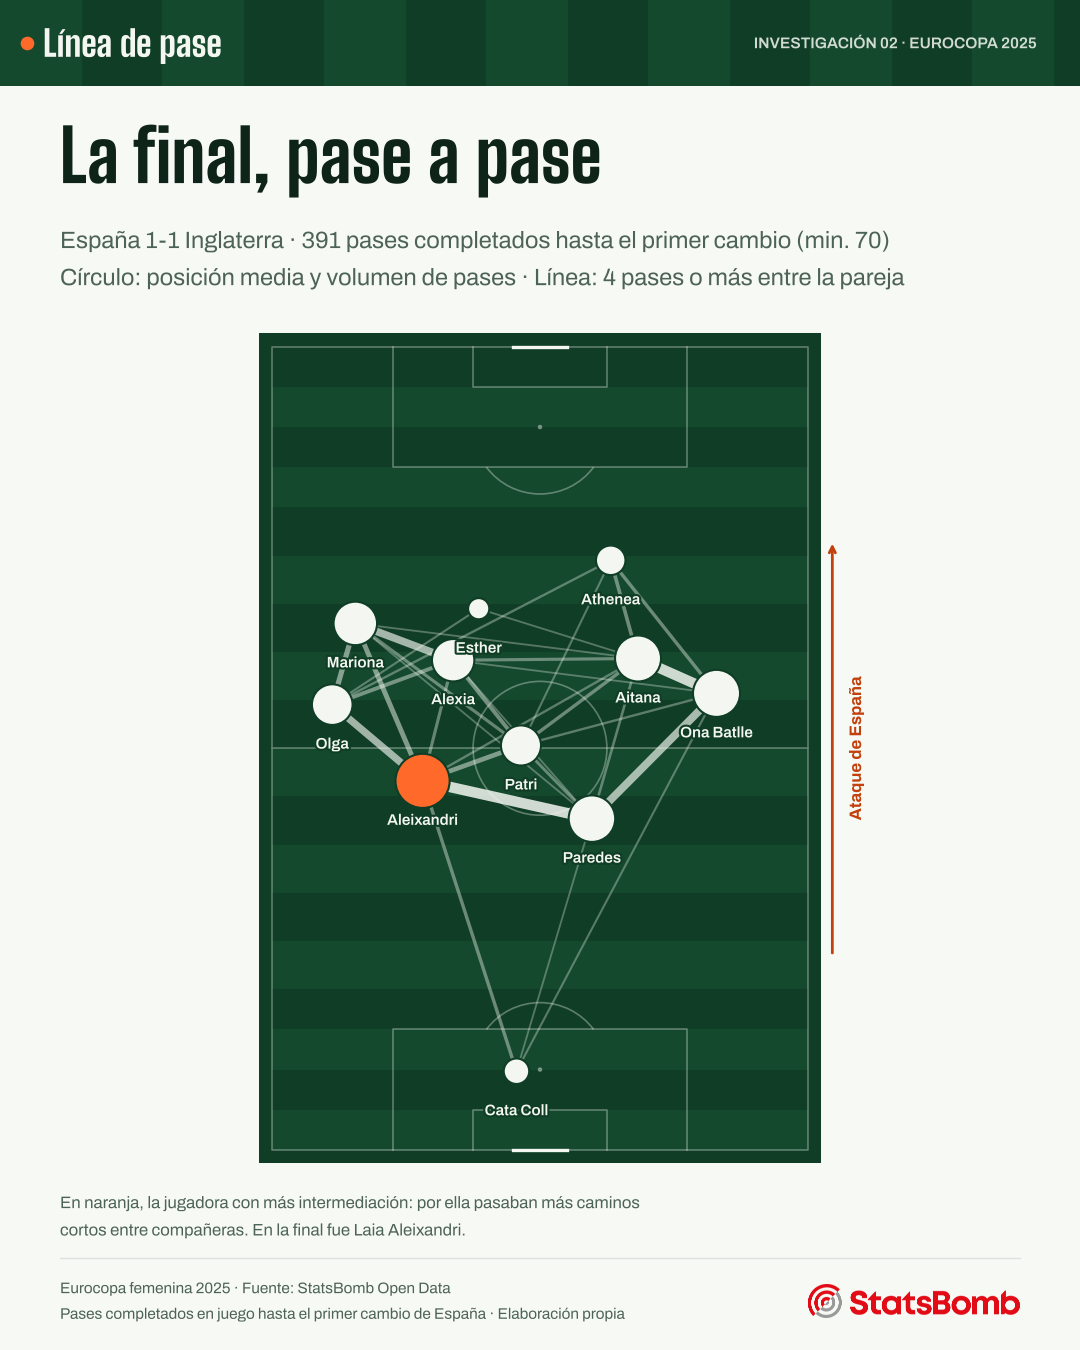

In [7]:
from IPython.display import Image, display
display(Image(filename=str(RAIZ / "graficos" / "01_red_final_instagram.png"), width=540))